In [ ]:
#yolo etiketlerini gözle kontrol etmek için gerekli olanları yükleniyor
import random 
import sys 
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
sys.path.append("../src")
from voc_to_yolo import CLASSES 
YOLO_DIR=Path("../data/yolo")
print( "CLASSES")

CLASSES


In [2]:
#her grupta resim ve etiket sayısı
for split in ["train","val","test"]:
    n_img=len(list((YOLO_DIR/"images"/split).glob("*.jpg")))
    n_lbl=len(list((YOLO_DIR/"labels"/split).glob("*.txt")))
    print(f"{split:6s} resim:{n_img:4d} etiket:{n_lbl:4d}")

train  resim:1260 etiket:1260
val    resim: 270 etiket: 270
test   resim: 270 etiket: 270


In [4]:
#kendi etiket yaptıgımız yeşil cizgilerle cizdigmizi kontrol etmek
lbl_path=next(YOLO_DIR.glob("labels/*/scratches_1.txt"))
print("dosya:",lbl_path)
print(lbl_path.read_text())

dosya: ../data/yolo/labels/train/scratches_1.txt
5 0.172500 0.457500 0.085000 0.795000
5 0.062500 0.950000 0.045000 0.060000



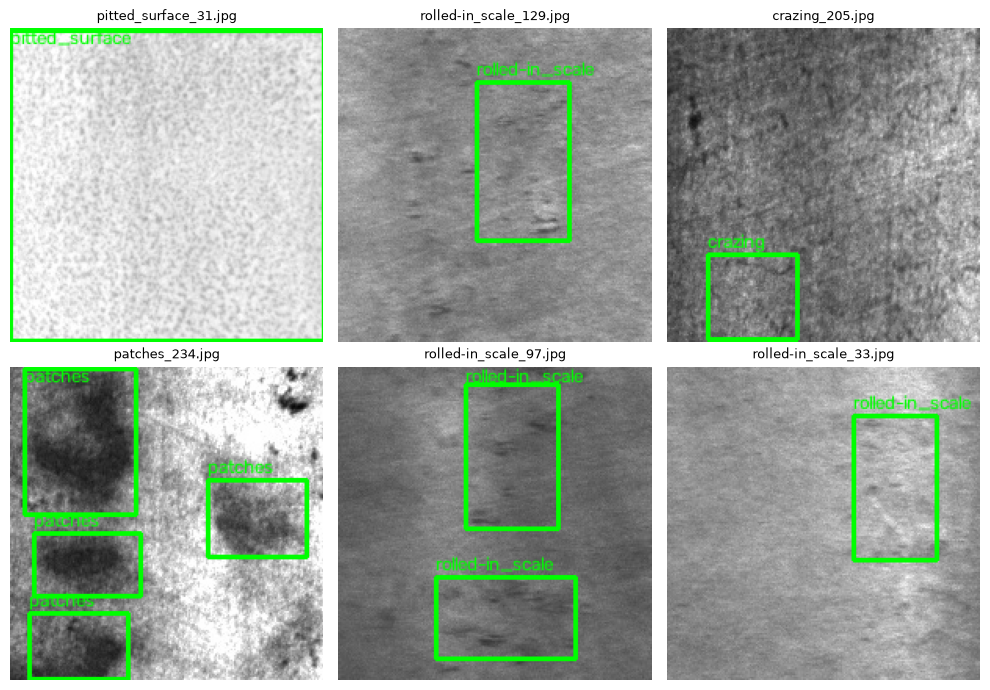

In [5]:
def draw_yolo(img_path, lbl_path):
    img = cv2.imread(str(img_path))
    h, w = img.shape[:2]
    for line in lbl_path.read_text().strip().splitlines():
        cls_id, xc, yc, bw, bh = line.split()
        xc, bw = float(xc) * w, float(bw) * w
        yc, bh = float(yc) * h, float(bh) * h
        x1, y1 = int(xc - bw / 2), int(yc - bh / 2)
        x2, y2 = int(xc + bw / 2), int(yc + bh / 2)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(img, CLASSES[int(cls_id)], (x1, max(y1 - 4, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 0), 1)
    return img


random.seed(0)
train_imgs = sorted((YOLO_DIR / "images" / "train").glob("*.jpg"))
samples = random.sample(train_imgs, 6)

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, img_path in zip(axes.flat, samples):
    lbl_path = YOLO_DIR / "labels" / "train" / f"{img_path.stem}.txt"
    ax.imshow(draw_yolo(img_path, lbl_path)[:, :, ::-1])
    ax.set_title(img_path.name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
fig.savefig("../reports/figures/04_yolo_label_check.png", dpi=150)
plt.show()

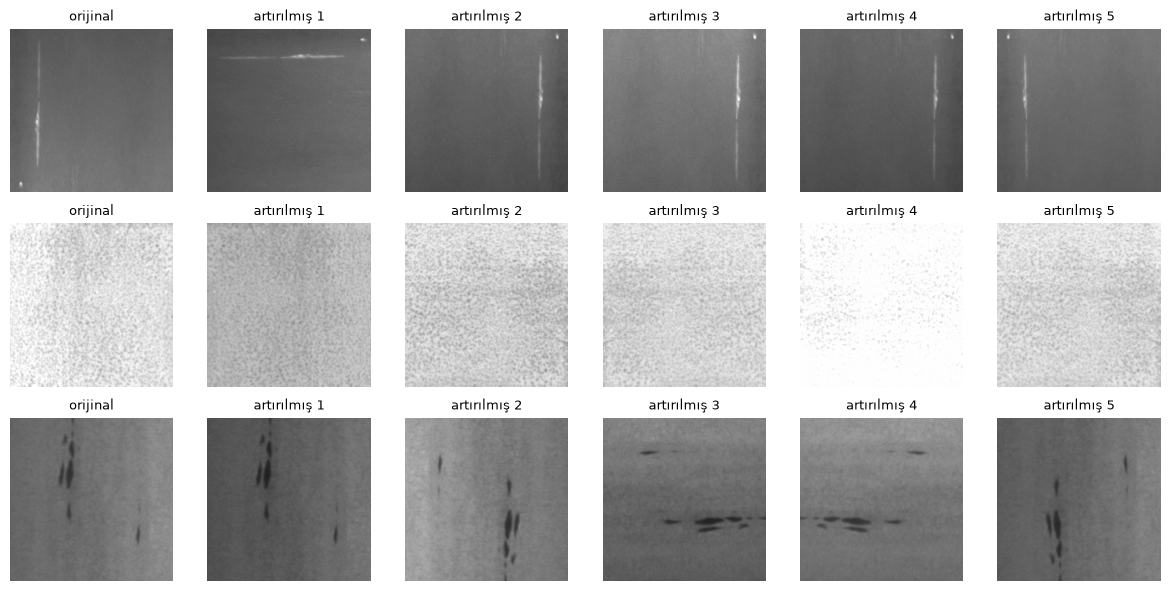

In [7]:
import torch
from PIL import Image
from torchvision.transforms import v2 as T

augment = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    T.RandomChoice([
        T.RandomRotation((0, 0)),
        T.RandomRotation((90, 90)),
        T.RandomRotation((180, 180)),
        T.RandomRotation((270, 270)),
    ]),
    T.ColorJitter(brightness=0.2, contrast=0.2),
])

torch.manual_seed(0)
examples = ["scratches_1.jpg", "pitted_surface_31.jpg", "inclusion_10.jpg"]

fig, axes = plt.subplots(len(examples), 6, figsize=(12, 6))
for row, name in enumerate(examples):
    img_path = next(YOLO_DIR.glob(f"images/*/{name}"))
    img = Image.open(img_path).convert("L")

    axes[row, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title("orijinal", fontsize=9)
    for col in range(1, 6):
        axes[row, col].imshow(augment(img), cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(f"artırılmış {col}", fontsize=9)
    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
fig.savefig("../reports/figures/05_augmentation.png", dpi=150)

## Katman 2 bulguları

**YOLO etiket kontrolü**
- 1260 / 270 / 270 resim ve etiket; sayılar tutuyor.
- `scratches_1` YOLO satırı elle hesaplananla aynı → formül doğru.
- 6 rastgele resimde kutular hatalara oturuyor → dönüşüm doğru.
- `patches_234`'te etiketlenmemiş koyu lekeler var (etiketler kusursuz değil).
- Crazing etiketleri tutarsız olabilir: bazen tüm resim, bazen küçük bir bölge.

**Veri artırma**
- Aynalama + 90° döndürme: hataları bozmuyor ✓
- Parlaklık/kontrast 0,3: pitted_surface gibi açık resimlerde doku kayboluyor (beyaza doyuyor).
- **Karar:** 0,2'ye düşürüldü. Doku seçilebiliyor; Katman 3'te pitted_surface başarısıyla kontrol edilecek.